# Figures S13-S20 - Bin-width sensitivity for an extensively sampled synthetic sequence

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figures show.** The same bin-width sweep as notebook 09, but for a 40-residue synthetic sequence (`DNKASSATAKTQTHNSGGAKAQHKGSTGAAKKPDGATDSQ`) simulated ~30x longer (10 replicates of 99,200 frames). Figures S13-S18 are the four-panel summaries at 5-120°, and S19/S20 overlay the mean curves.

**What to look for.** With this much sampling the histograms are well populated even at 5°, so the bin-width dependence is roughly half that of the FS-peptide (compare the spread between the 5° and 120° curves here with notebook 09), and in particular the 5° curve no longer jumps away from the 15° one. A residual, smooth dependence on bin width remains - the Hellinger distance between two genuinely different continuous distributions does grow as the resolution increases - but the finite-sampling part of the effect is what shrinks with more data.

**Differences from the published S19/S20.** The published curves cluster more tightly and show sharp peaks at residues 17, 25 and 33. Both features were artefacts of the precomputed EV reference as implemented at the time (see below): the peaks came from the per-residue tables being looked up with the neighbouring residue's identity, and the tight clustering from a resampling scheme that pinned reference samples to bin centres, which made the reference look identical at every bin width by construction. The curves here are the correct computation.

**No EV simulations for this system.** This is the one main analysis that uses SOURSOP's *precomputed* excluded-volume reference: when no `reference_list` is given, `SamplingQuality` looks up, for every residue, the EV φ/ψ distribution tabulated for that amino acid in the context of its neighbours, and resamples it to match the trajectory length. Two things changed in SOURSOP 2.0.6 that affect this path and therefore the values relative to the published figures: the lookup previously keyed on the neighbouring residue rather than the residue itself, and the resampling did not populate the ±180° tails. Both are fixed, so the reference here is the correct one; the qualitative message - a well-sampled system is much less sensitive to the bin width - survives, but less starkly than the published figure suggested.

**Runtime.** Each width re-reads ~2 GB of trajectory; expect this notebook to take a while.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)
from penguin_helpers import plot_bin_width_comparison
from soursop.sssampling import SamplingQuality
from soursop.sstools import find_trajectory_files

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Locate the replicates

In [2]:
synth_trj, synth_top = find_trajectory_files(DATA_DIR / "synthetic_sequence" / "full", num_replicates=10)
print(len(synth_trj), "replicates")

10 replicates


## Four-panel summaries at each bin width (Figures S13-S18)

DNKASSATAKTQTHNSGGAKAQHKGSTGAAKKPDGATDSQ
.........1.........2.........3.........4


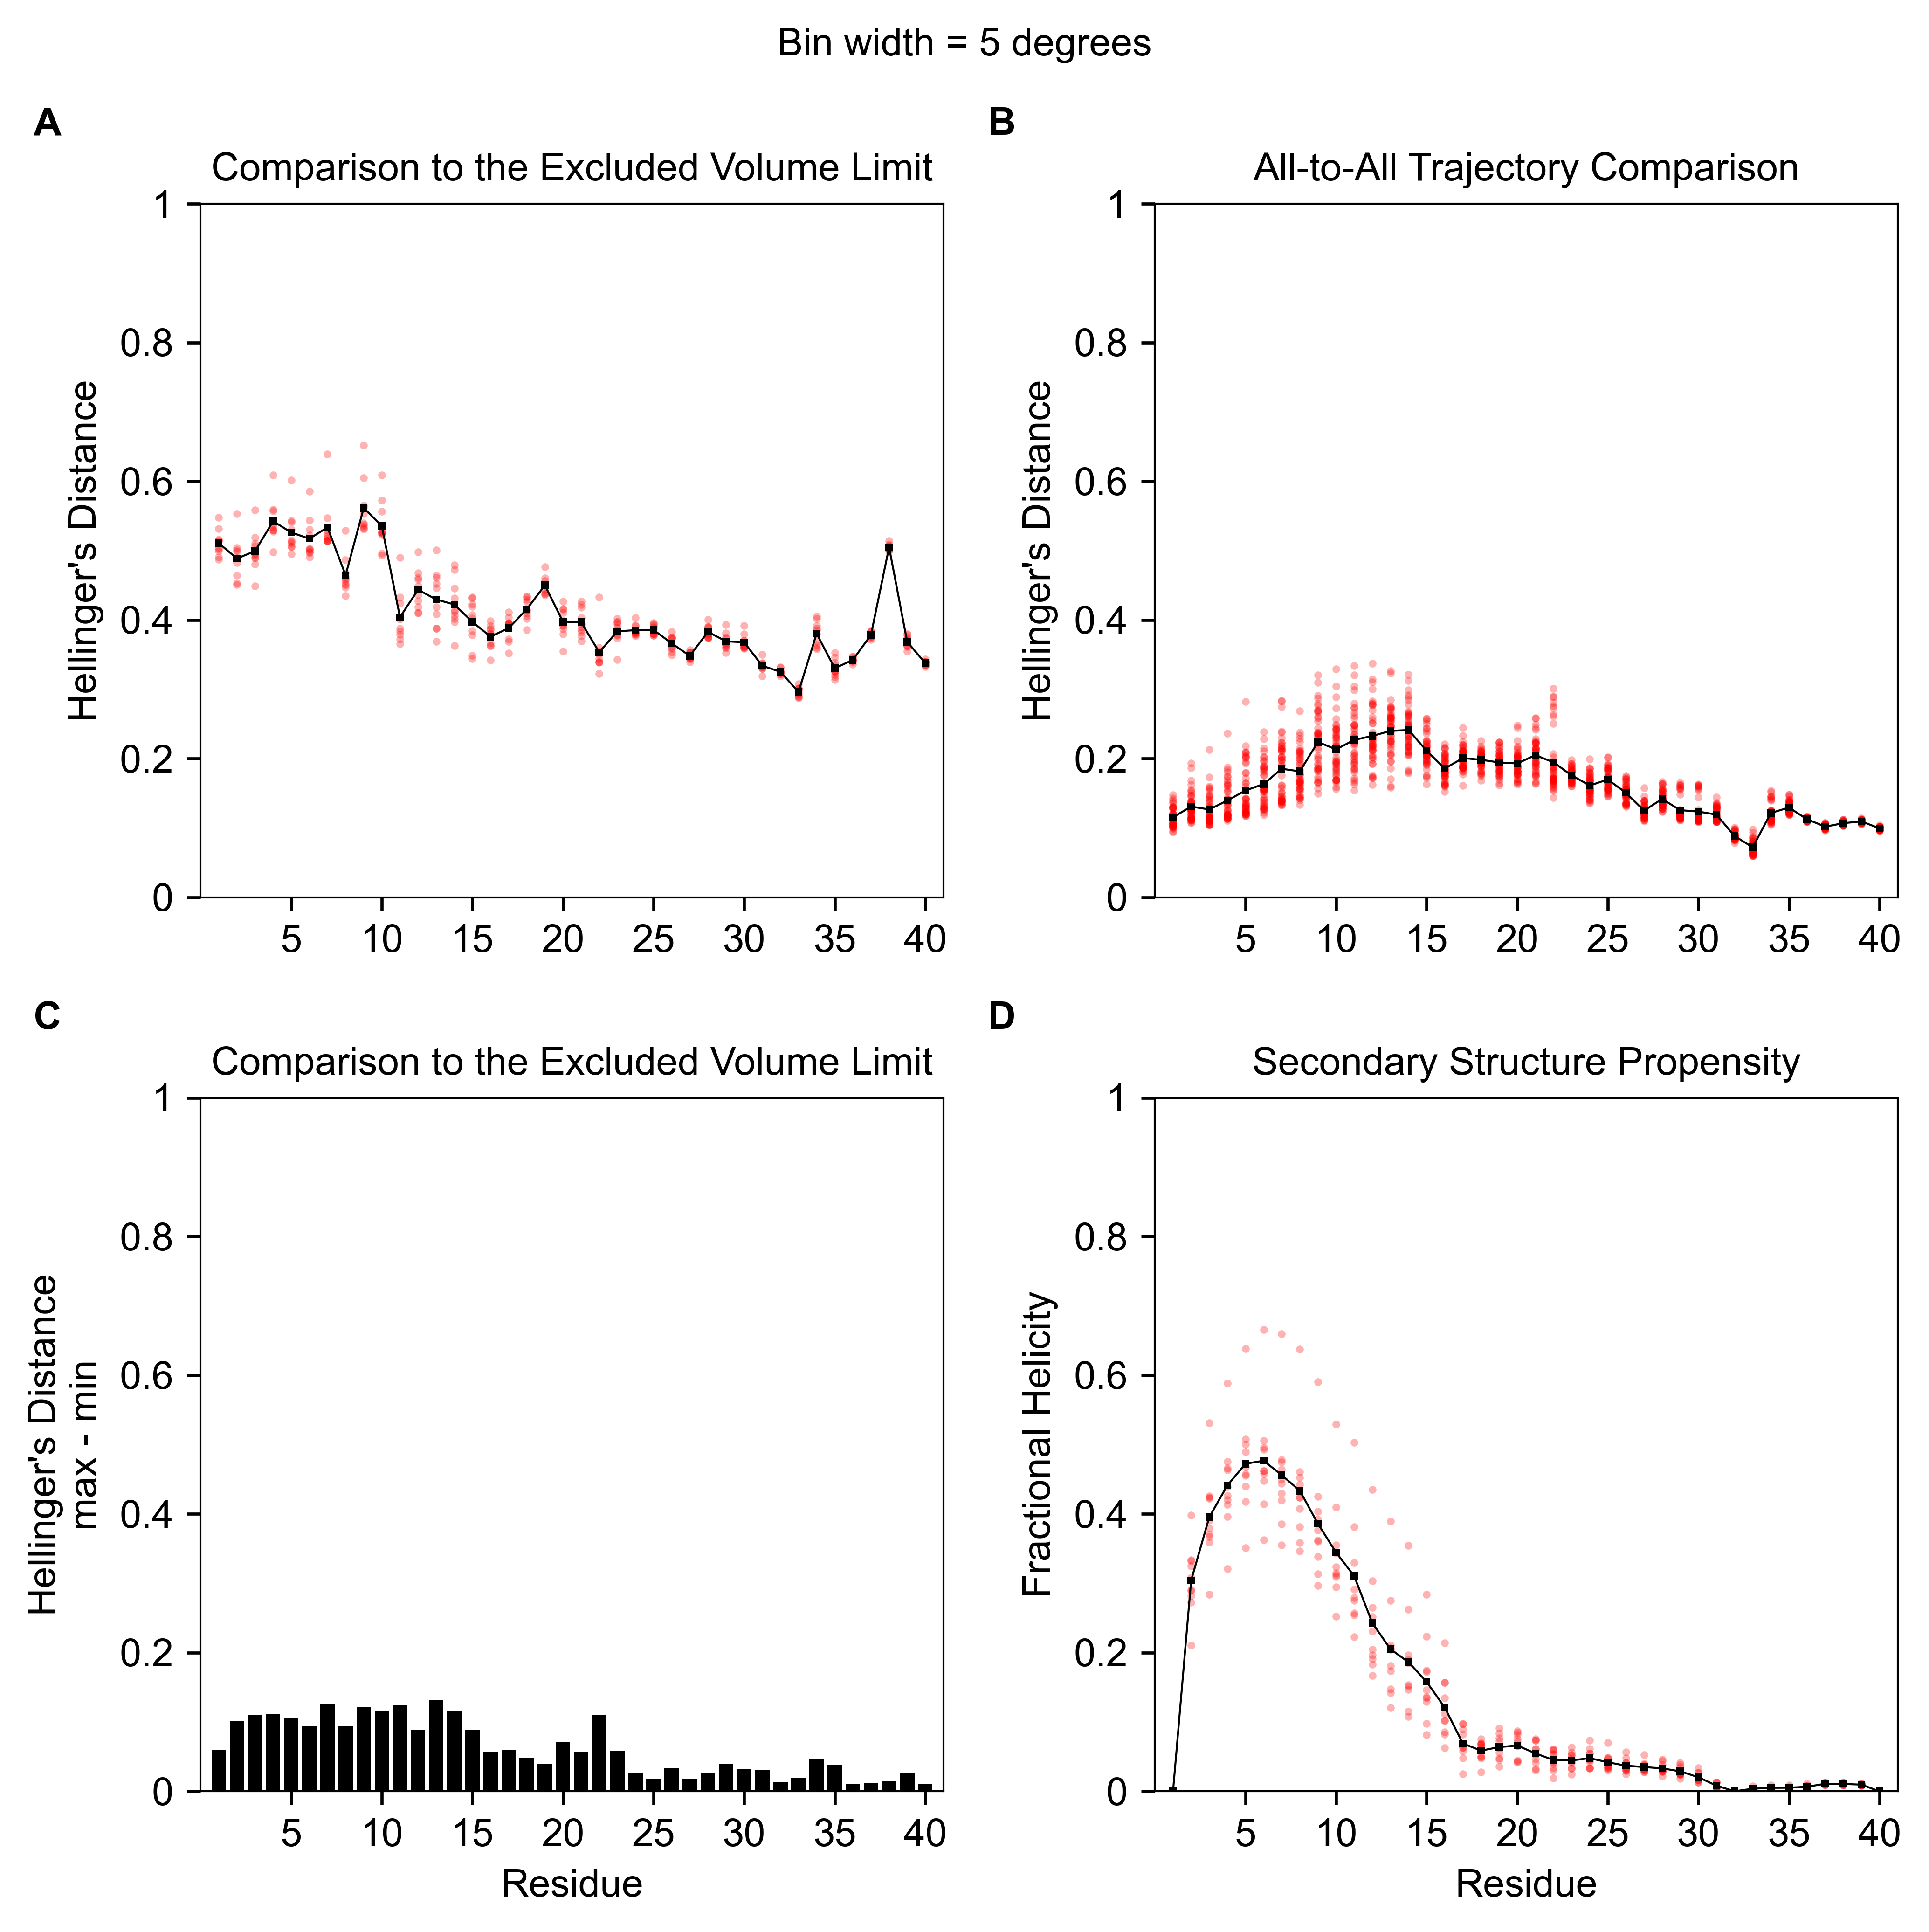

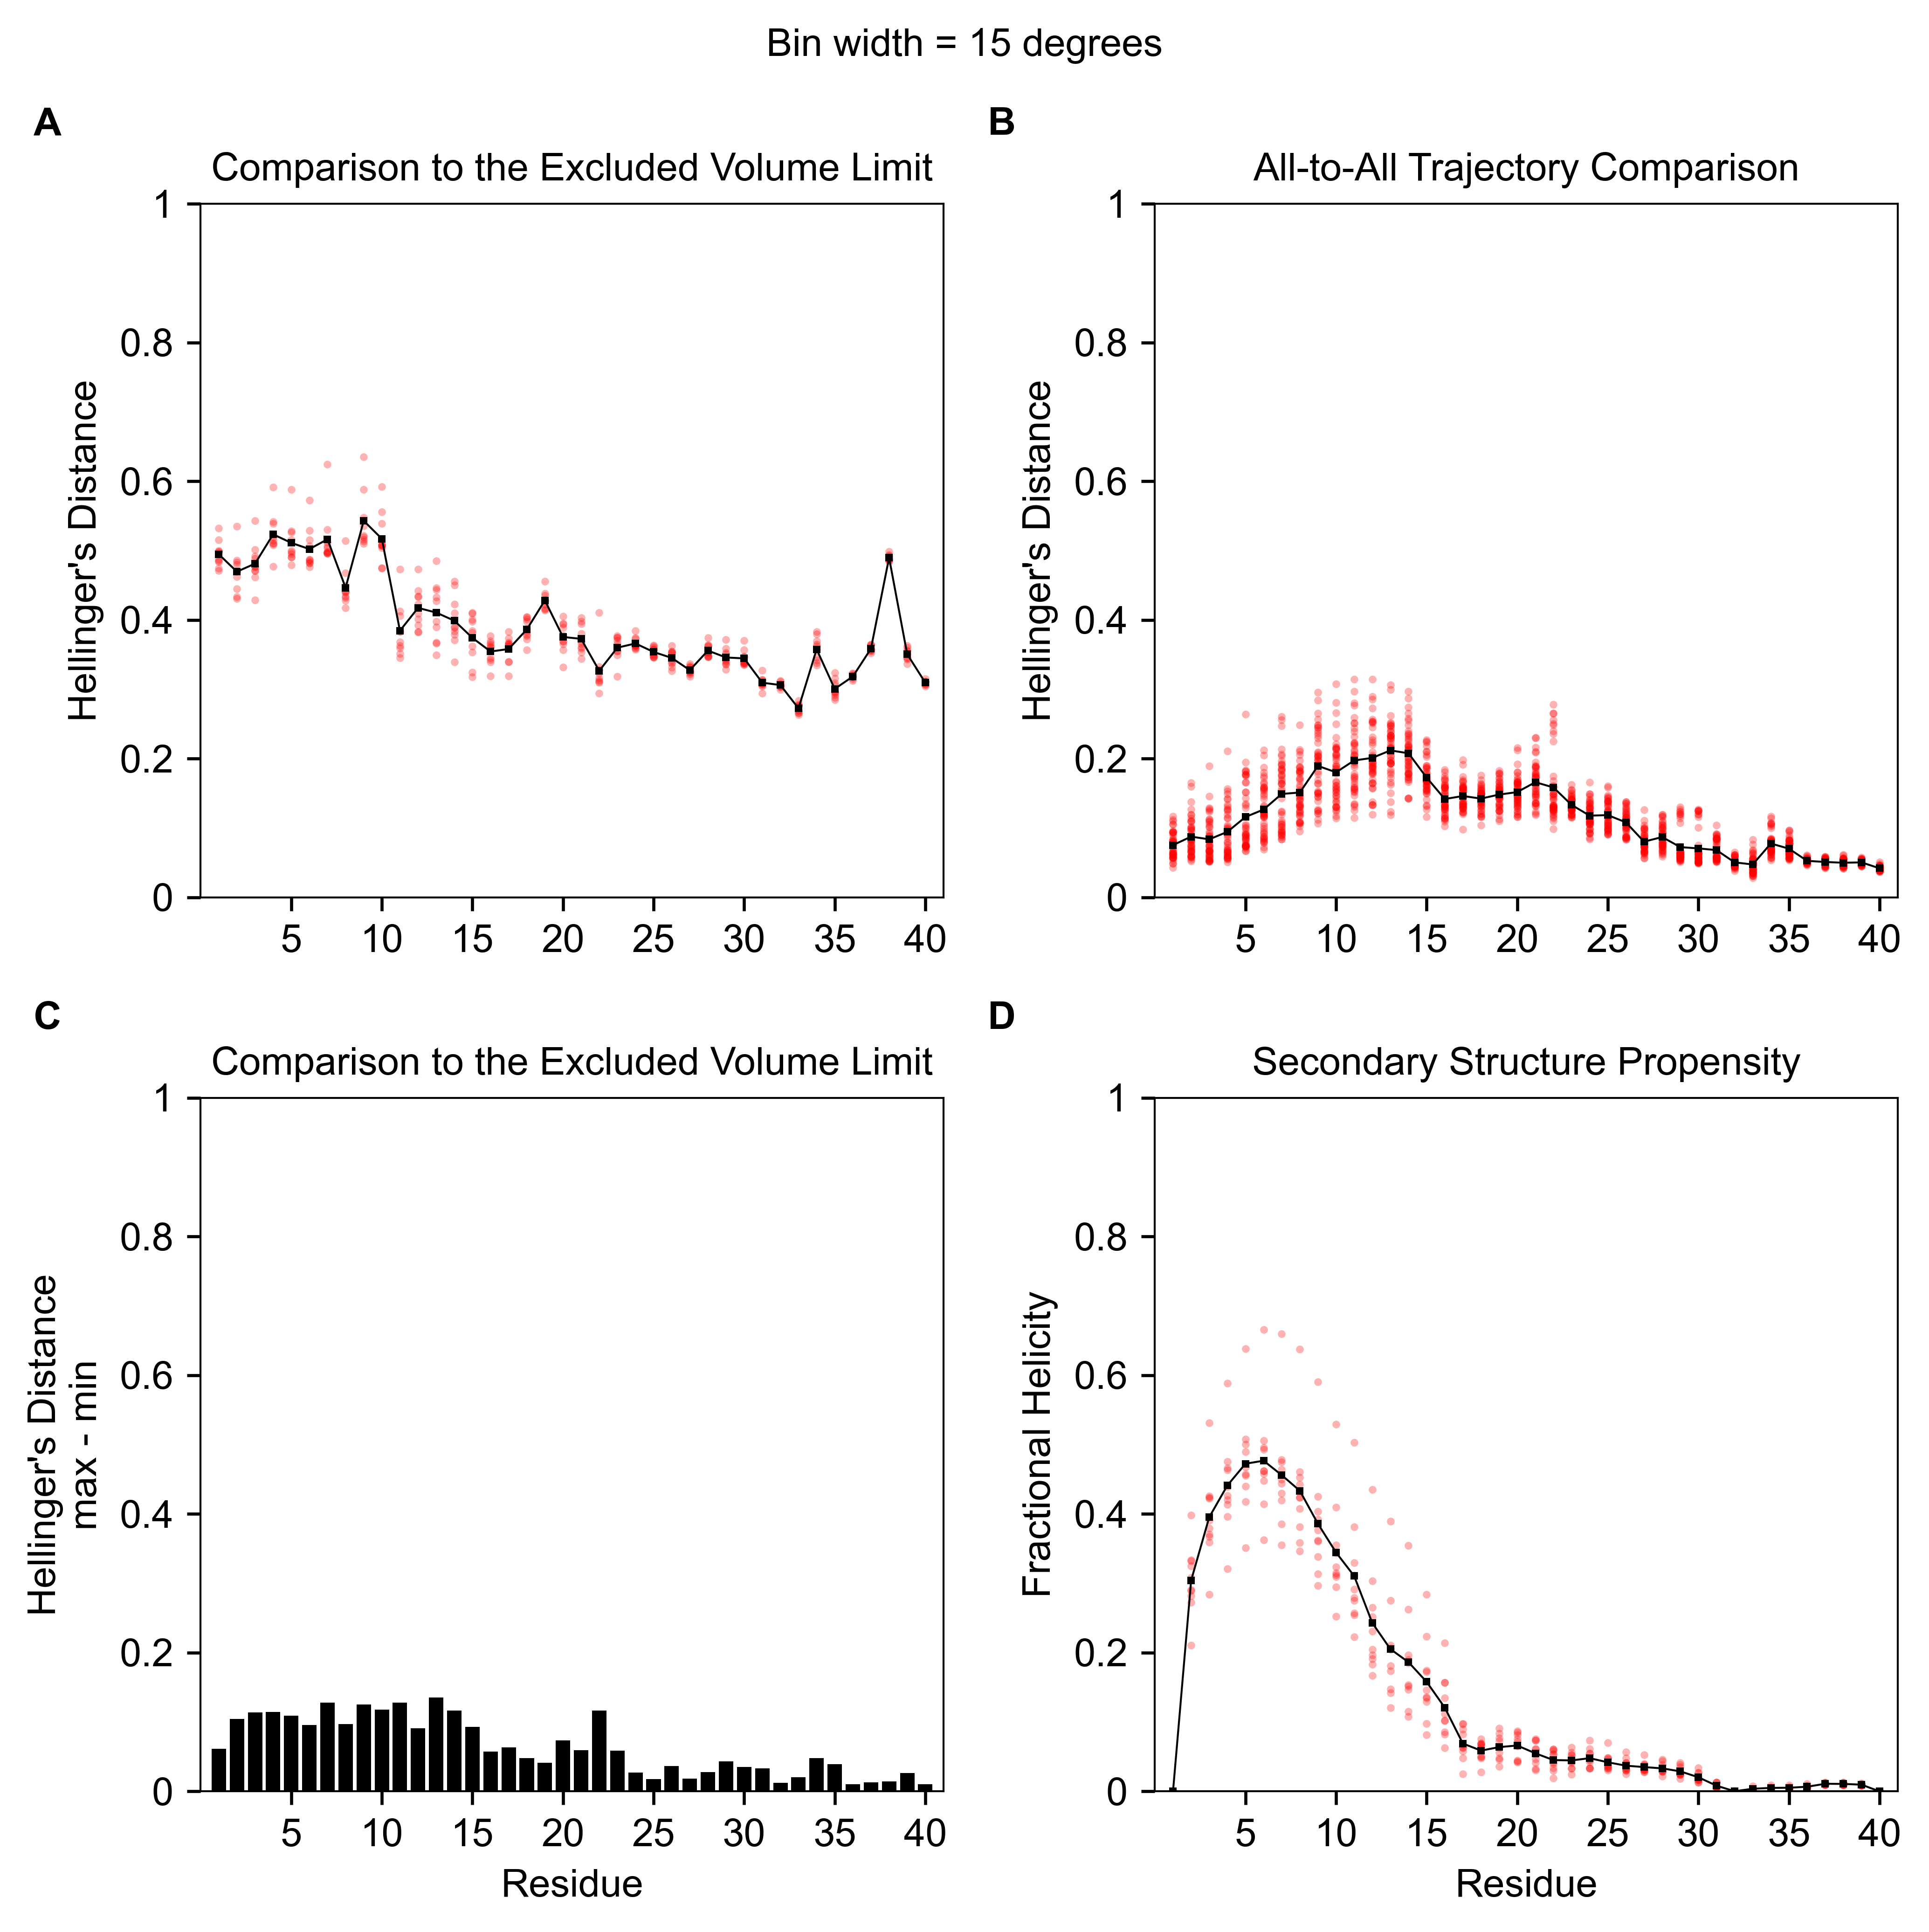

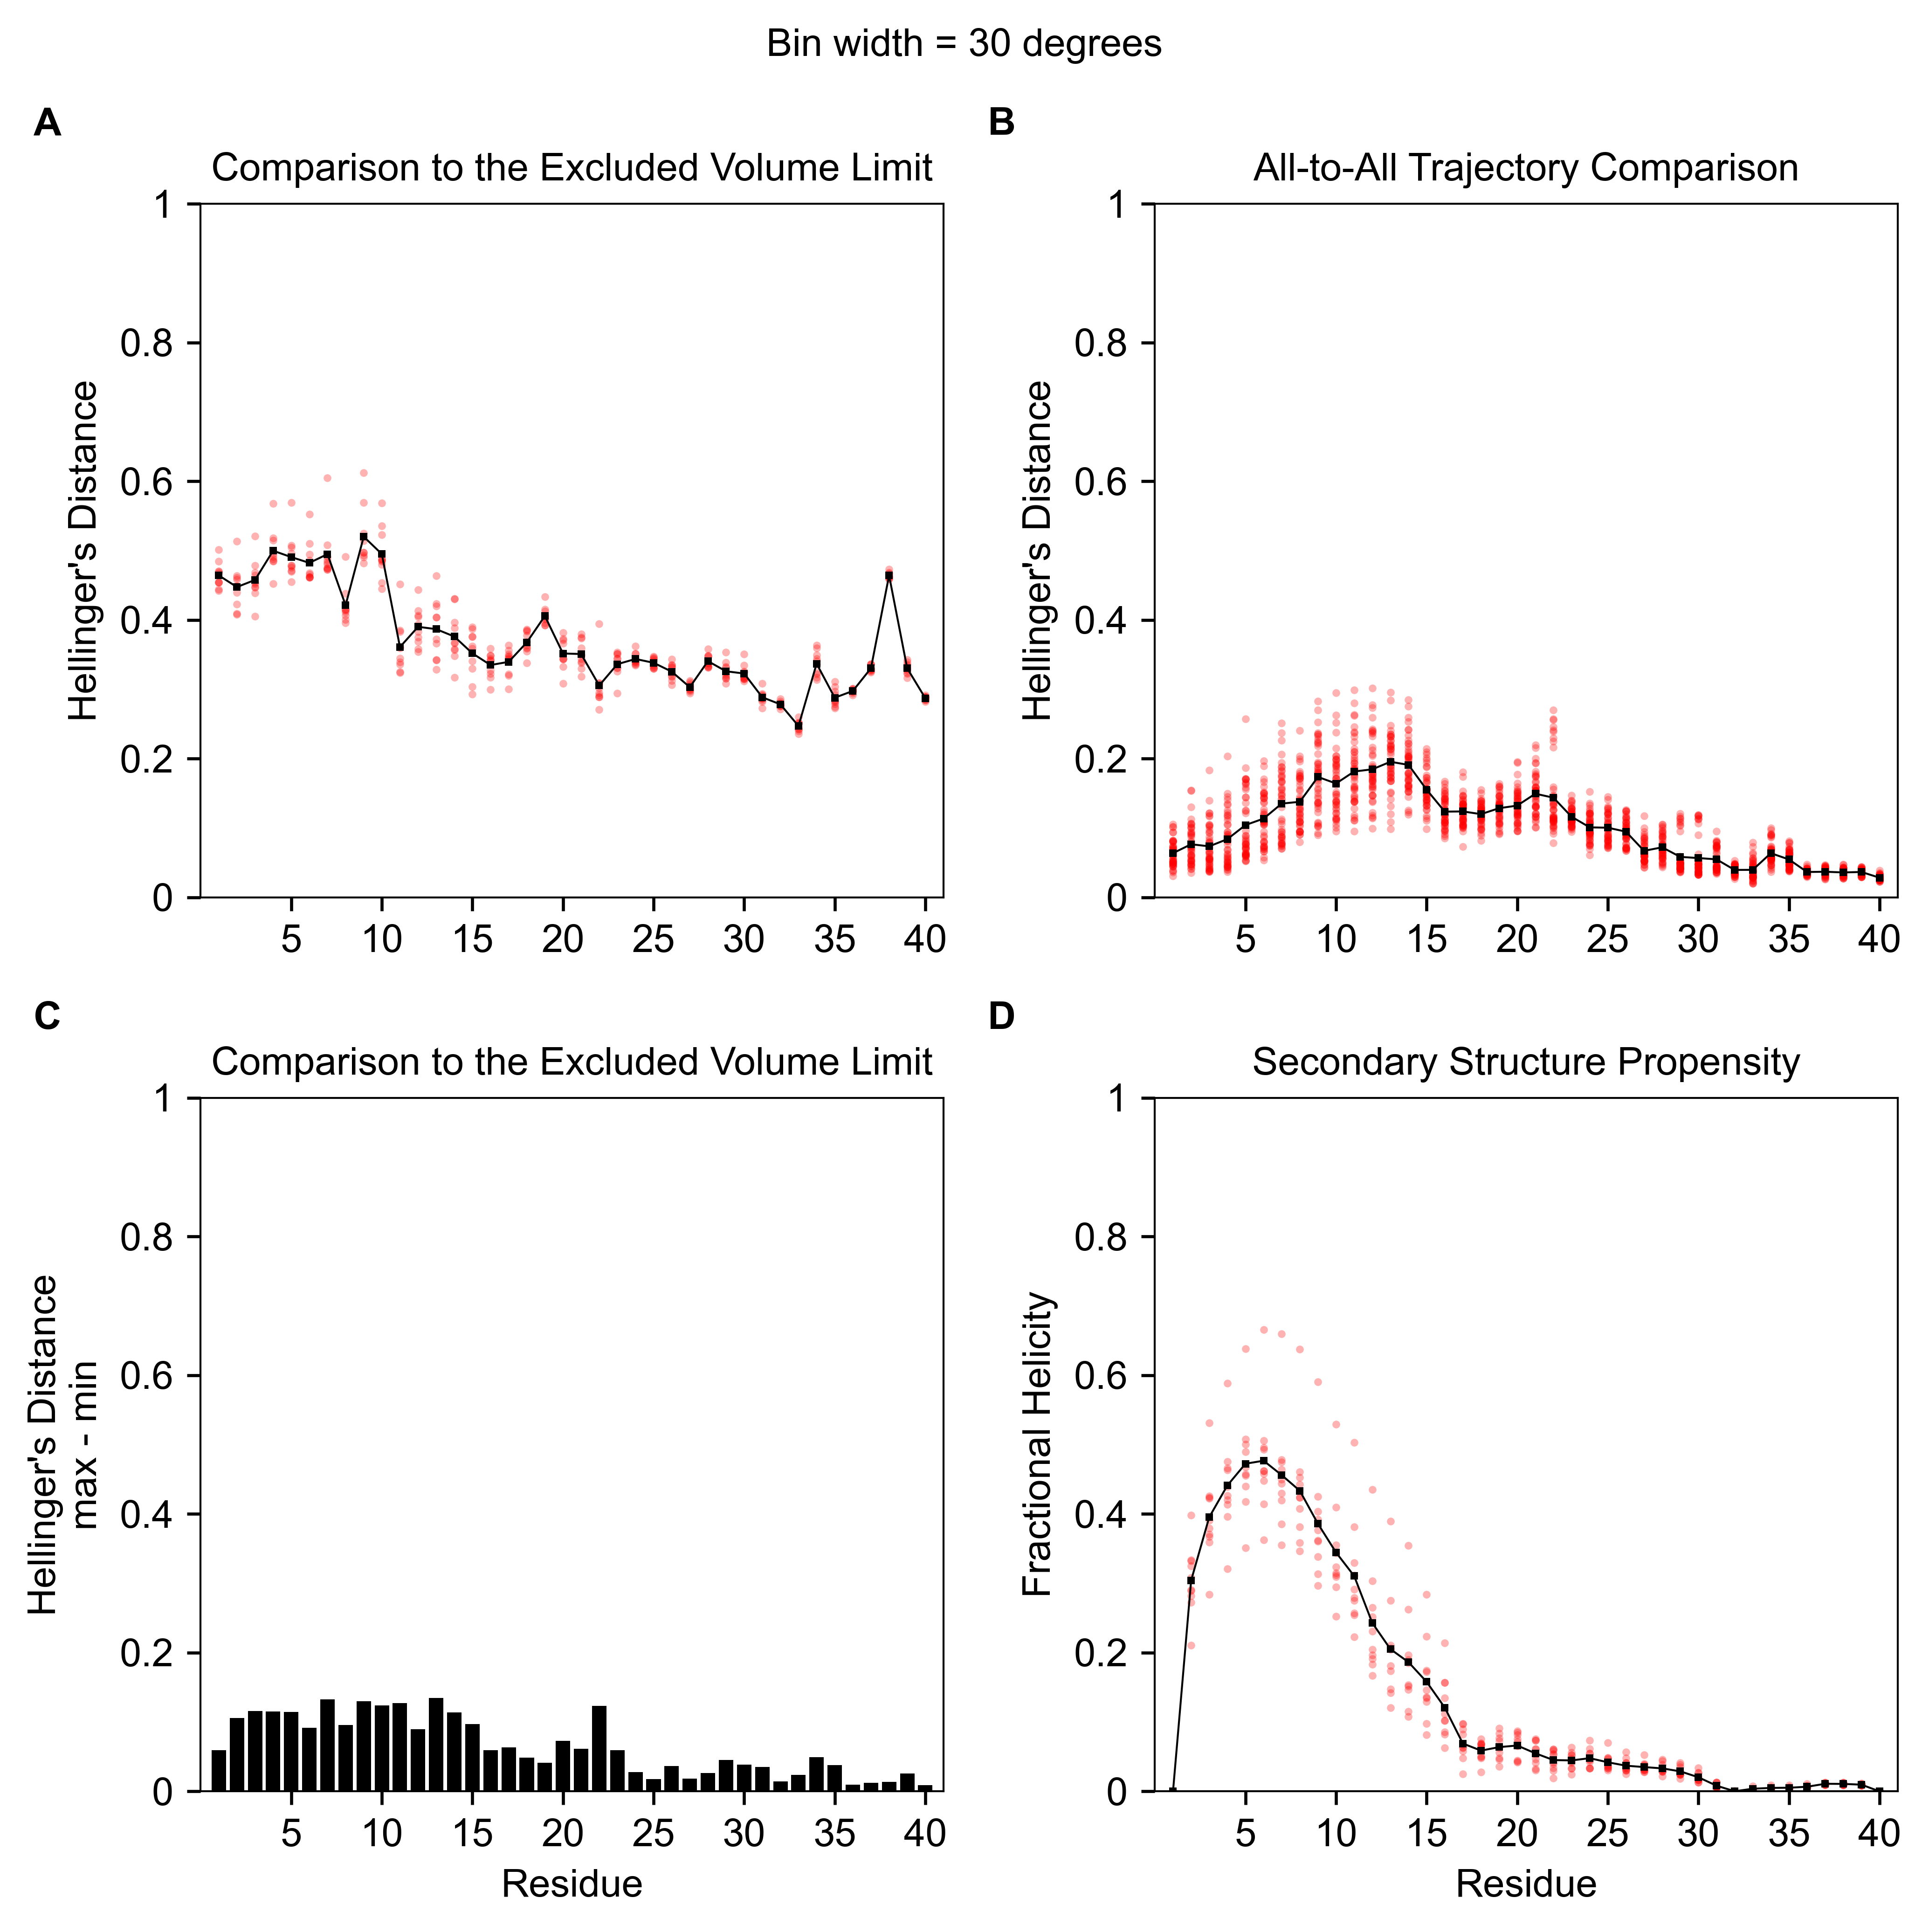

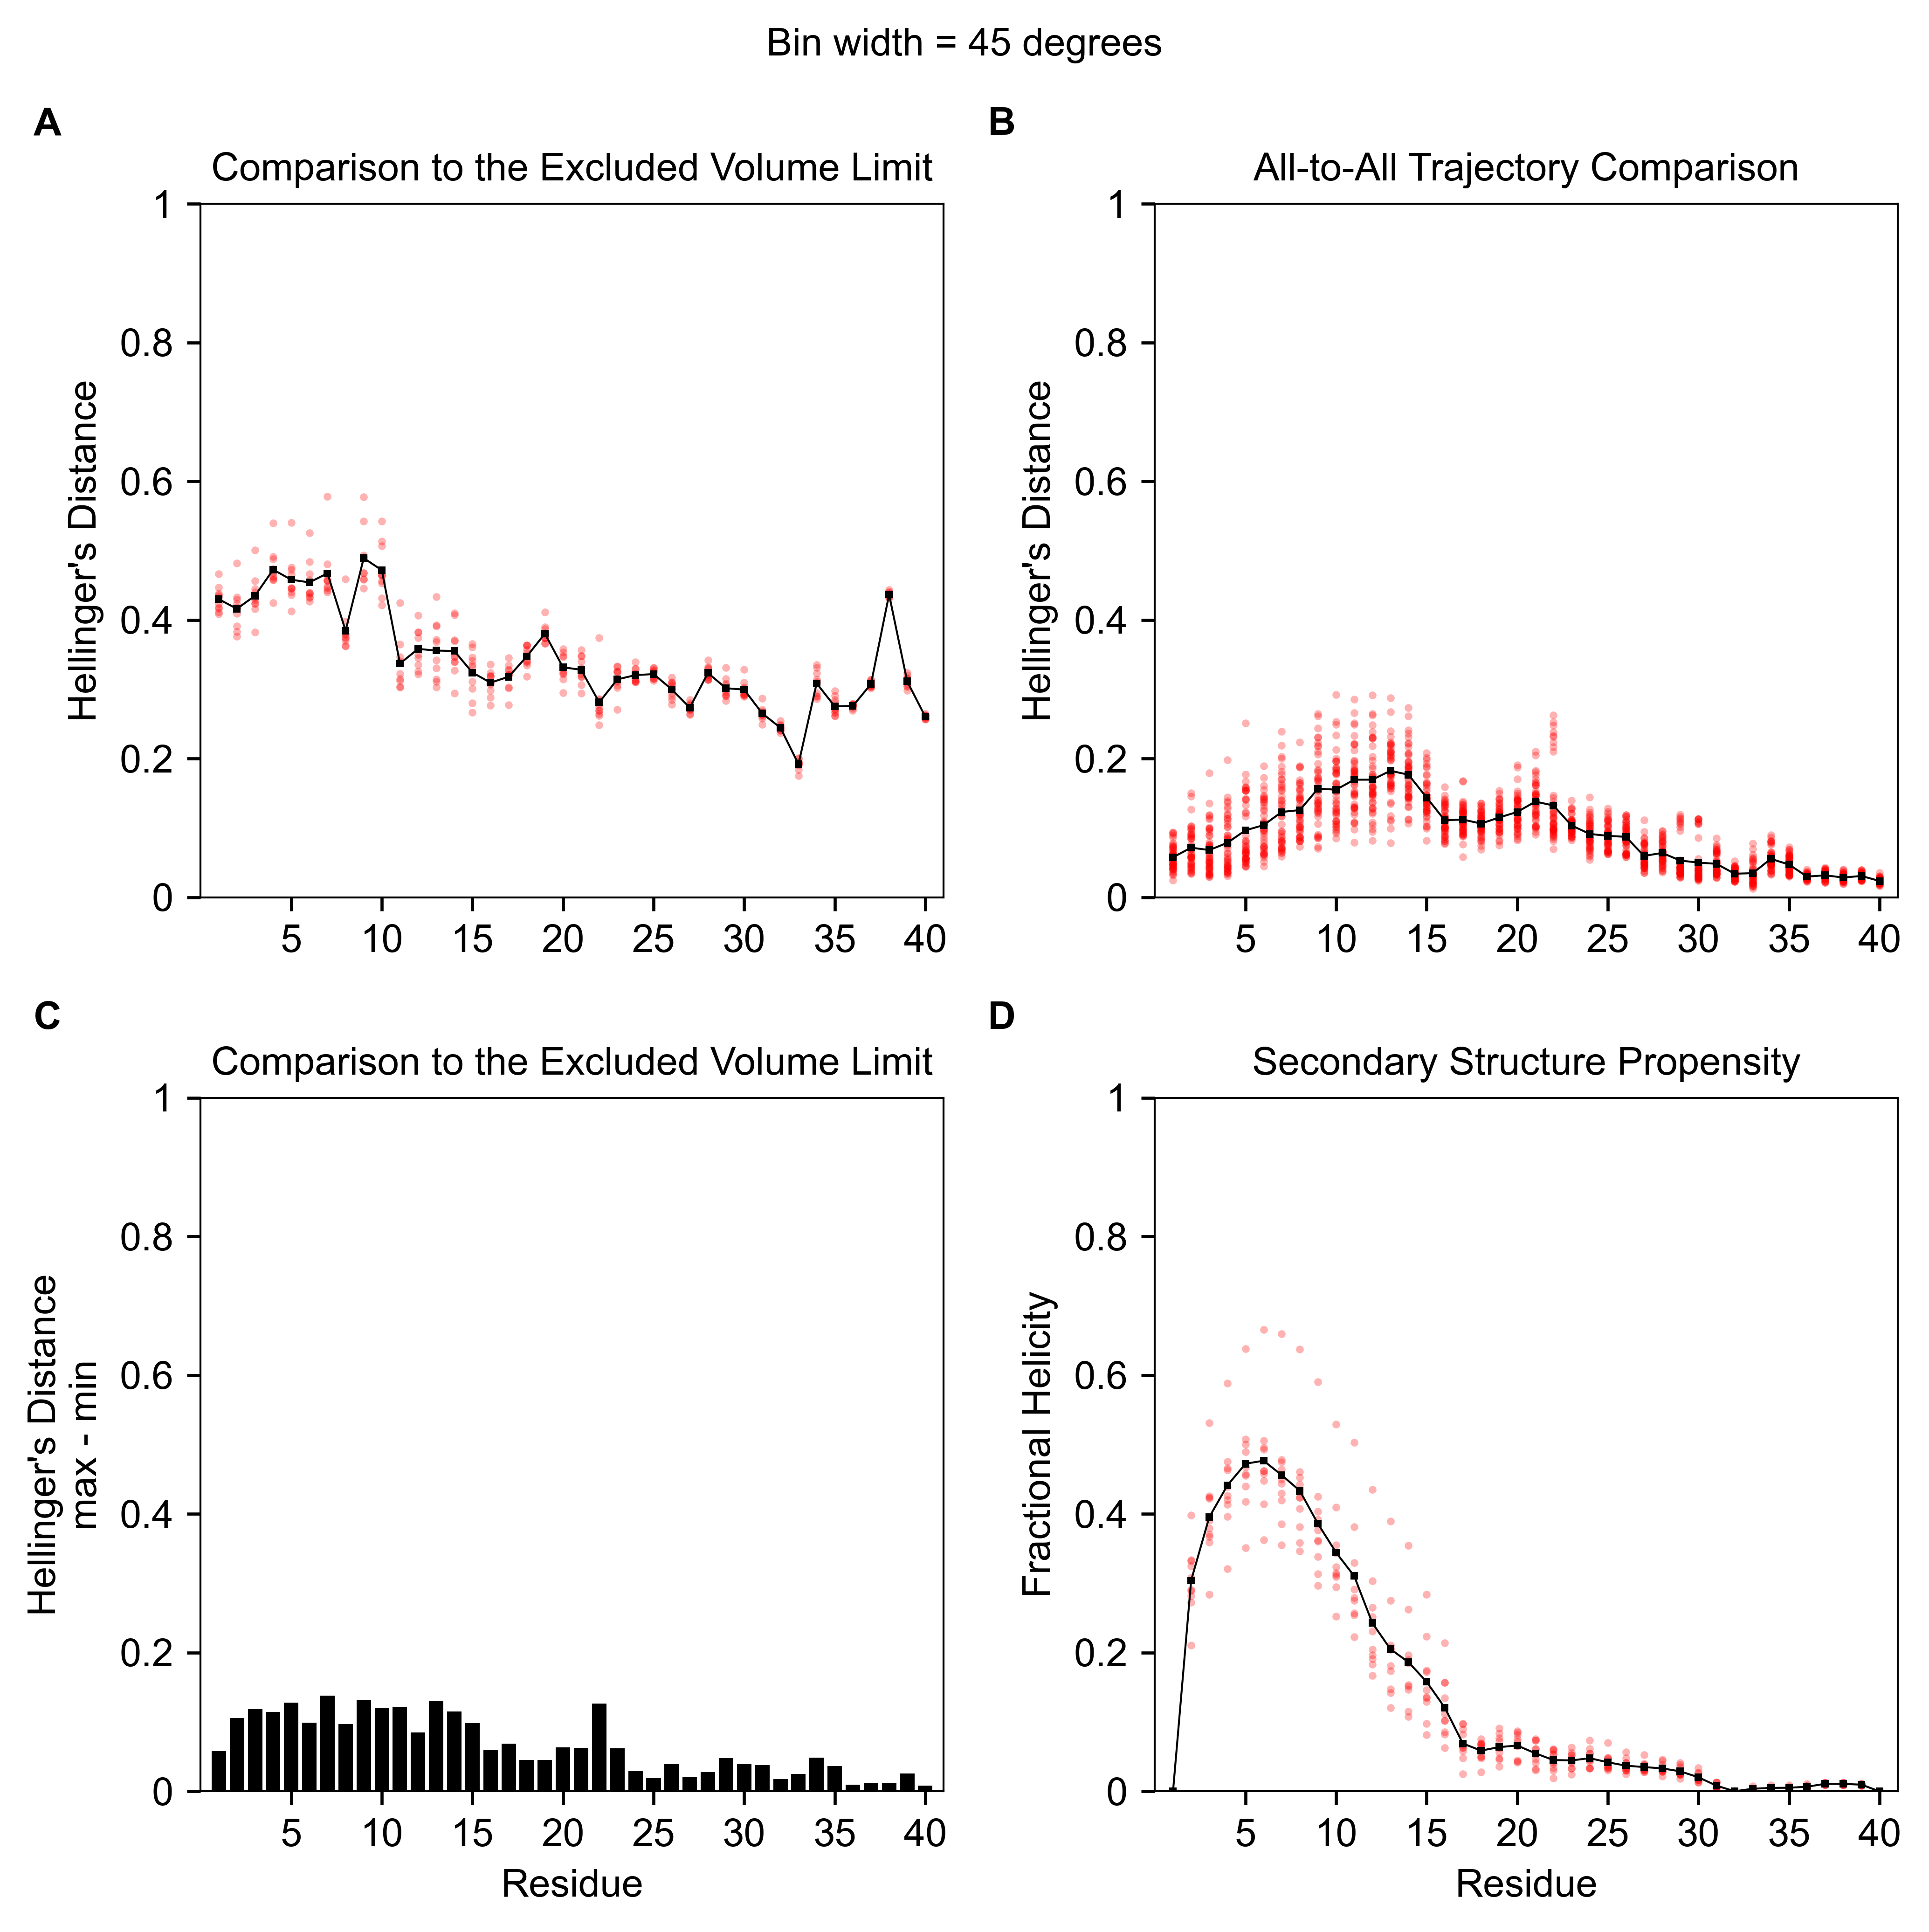

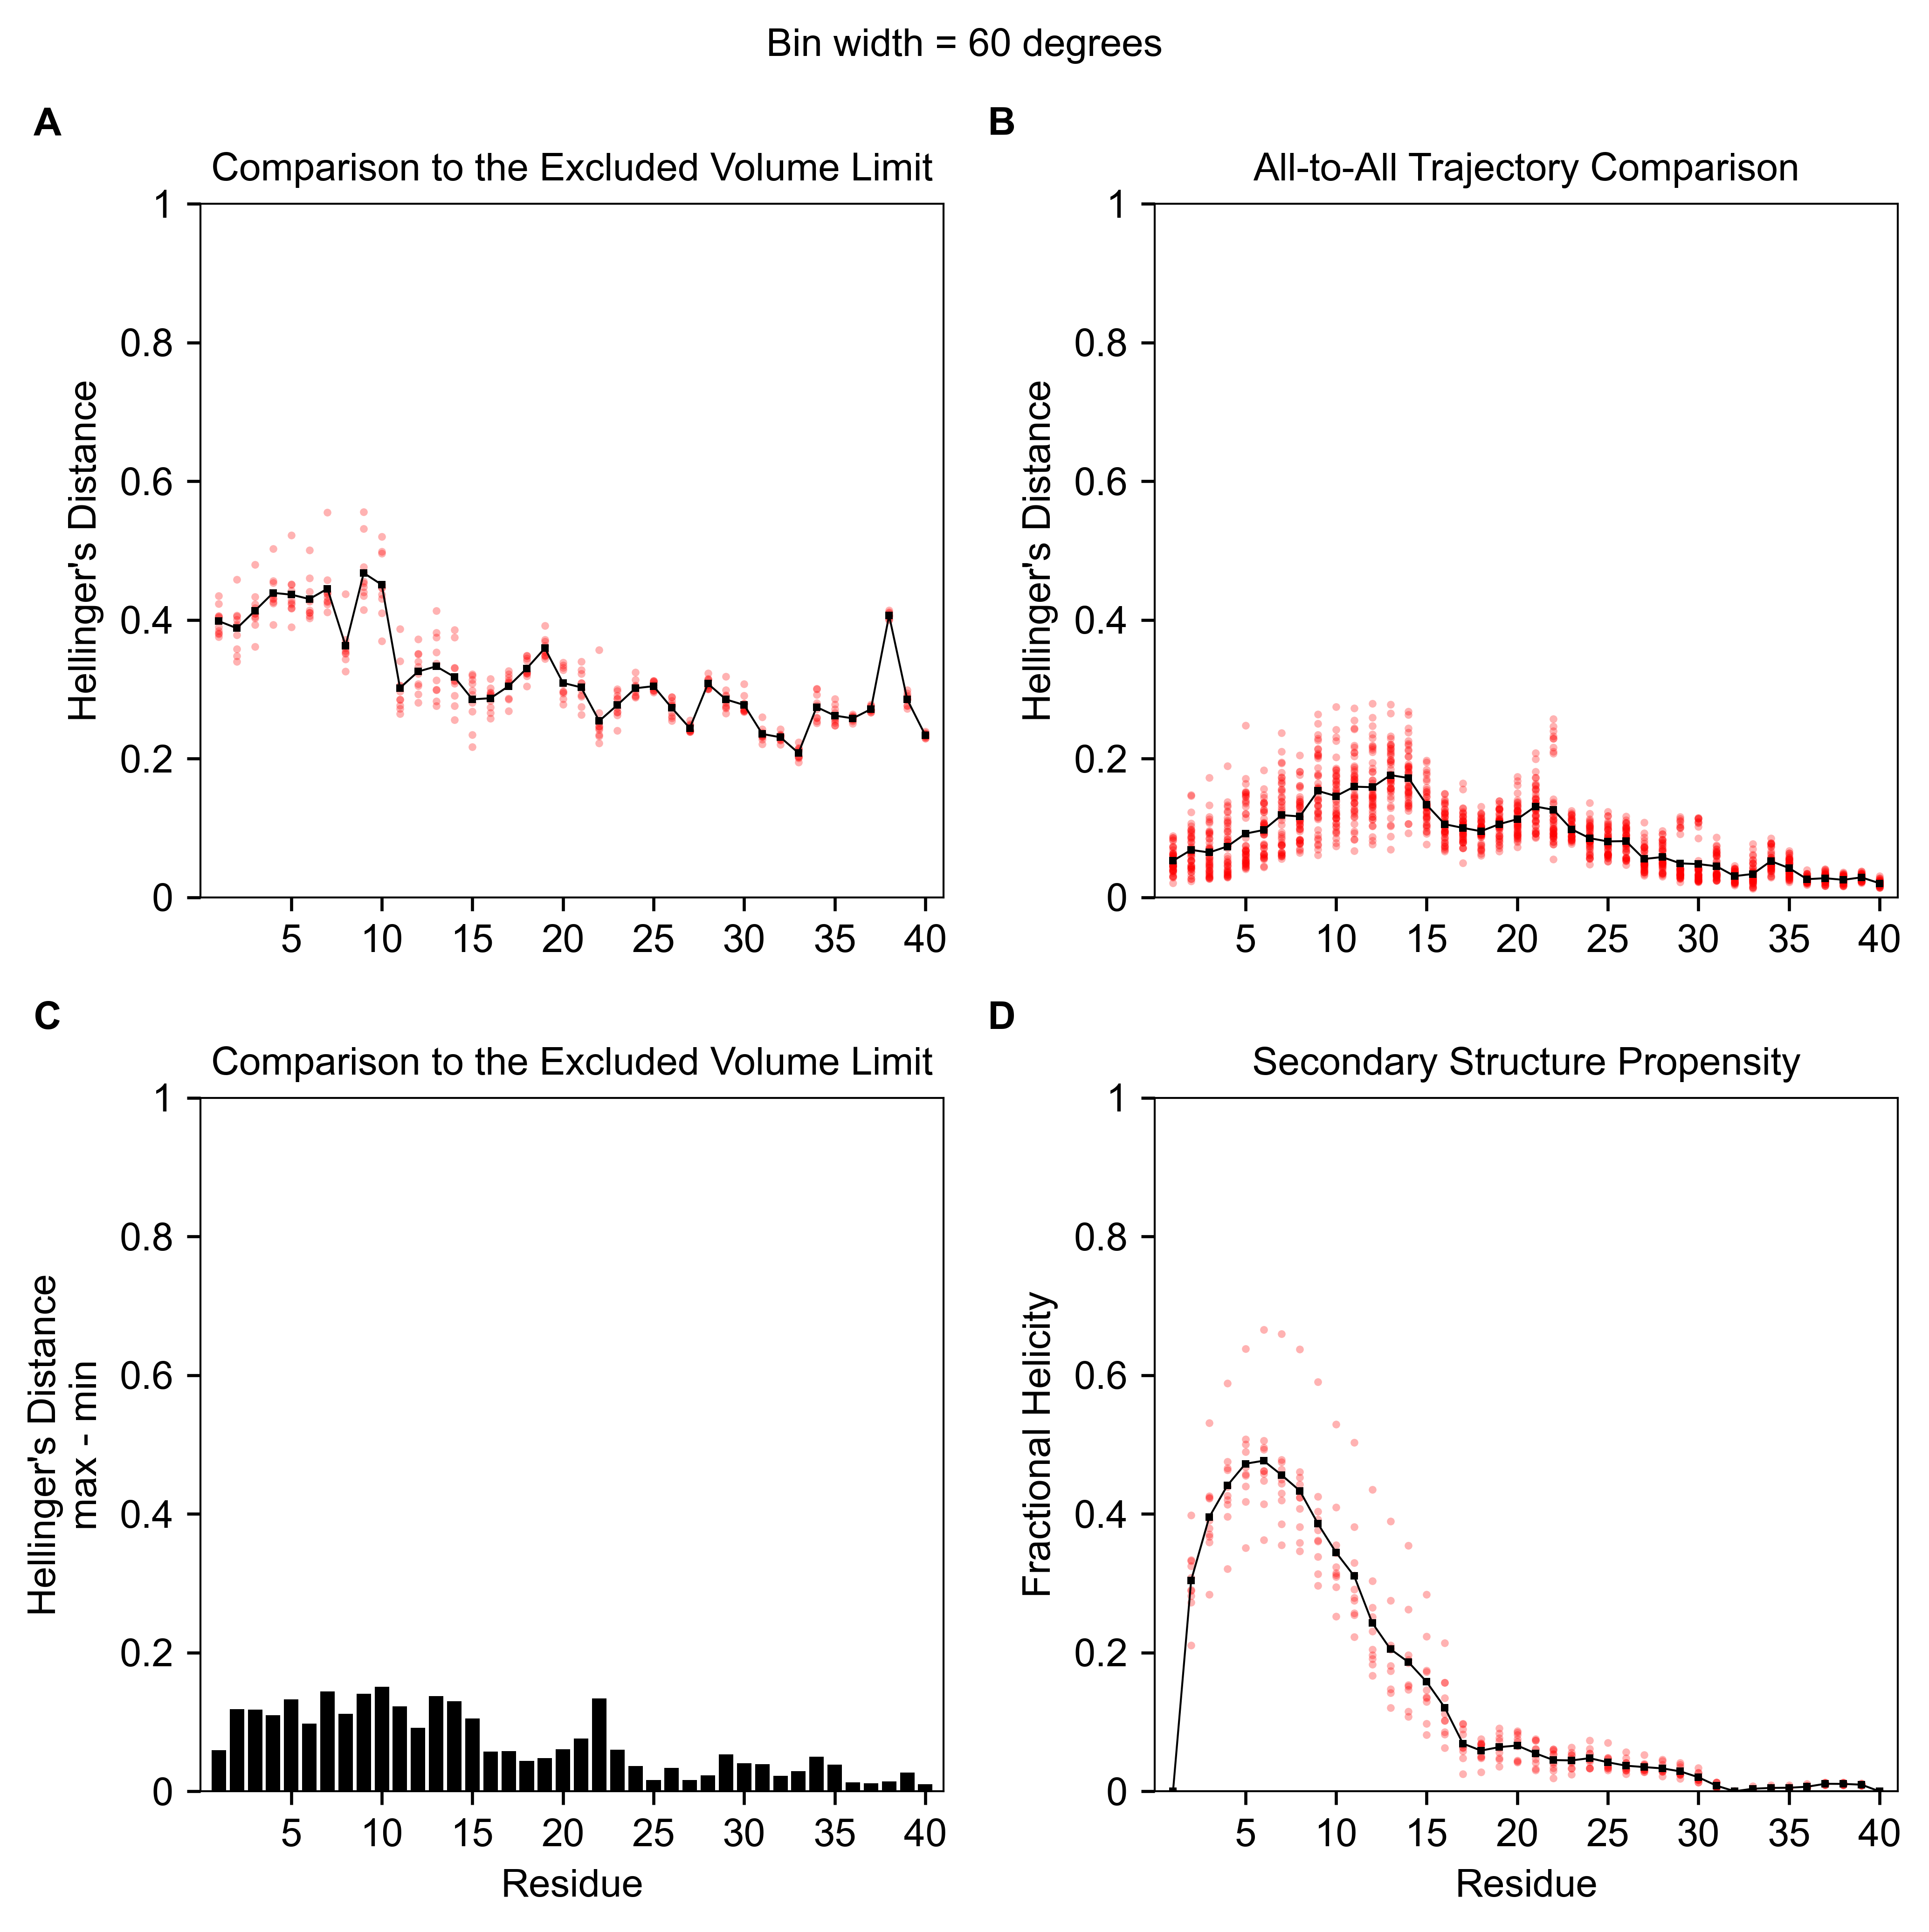

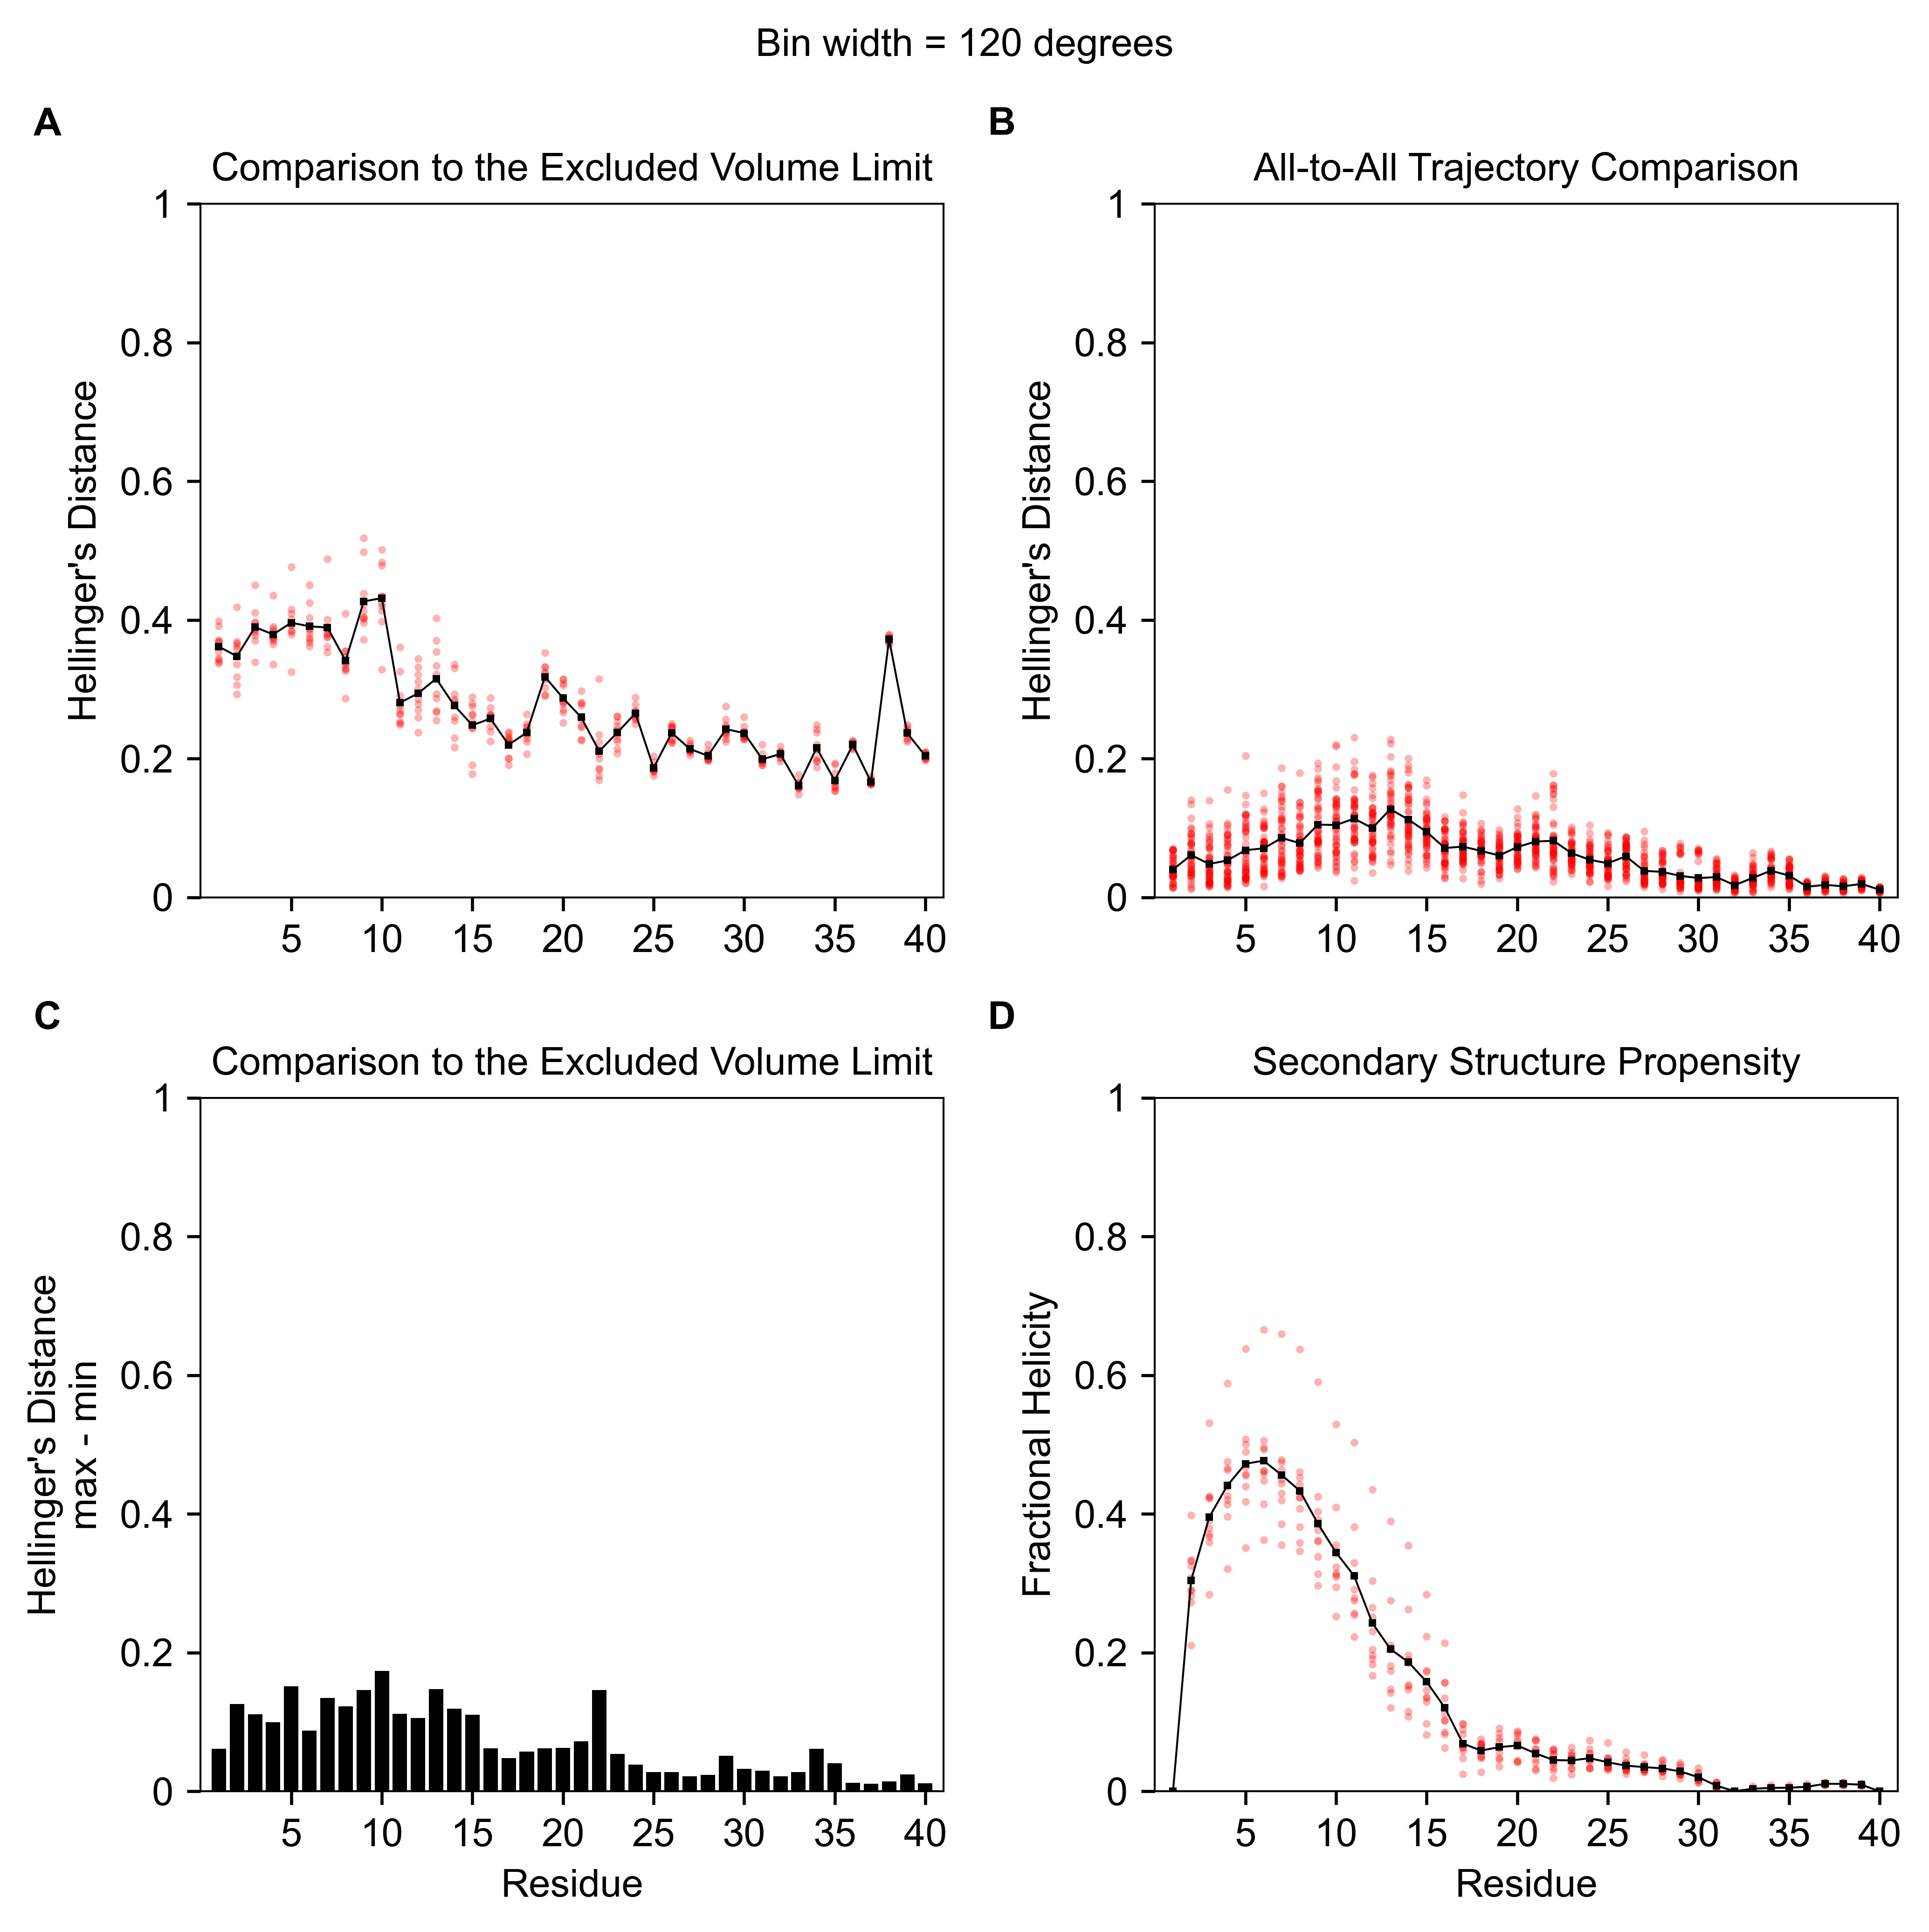

In [3]:
bin_widths = [5, 15, 30, 45, 60, 120]

ev_means, ata_means = [], []
for bw in bin_widths:
    qual = SamplingQuality(synth_trj, top_file=synth_top[0], method="2D angle distributions",
                           bwidth=np.deg2rad(bw), seed=0)
    if bw == bin_widths[0]:
        sequence = print_sequence(qual)
    fig, axd = penguin_figure(qual, dihedral="2D", increment=5, figsize=(7, 7), fontsize=10,
                              panel_labels=("A", "B", "C", "D"),
                              title=f"Bin width = {bw} degrees",
                              save_path=figure_path("si_figures", "synth_bin_width", f"synth_2D_{bw}.pdf"))
    ev_means.append(np.mean(np.asarray(qual.hellingers_distances()), axis=0))
    ata_means.append(np.mean(np.asarray(qual.get_all_to_all_2d_trj_comparison()), axis=0))
ev_means = np.array(ev_means); ata_means = np.array(ata_means)

## Replicate-mean curves across bin widths (Figures S19 and S20)

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'All-to-All Trajectory Mean Comparison Across Bin Widths'}, xlabel='Residue', ylabel="Hellinger's Distance">)

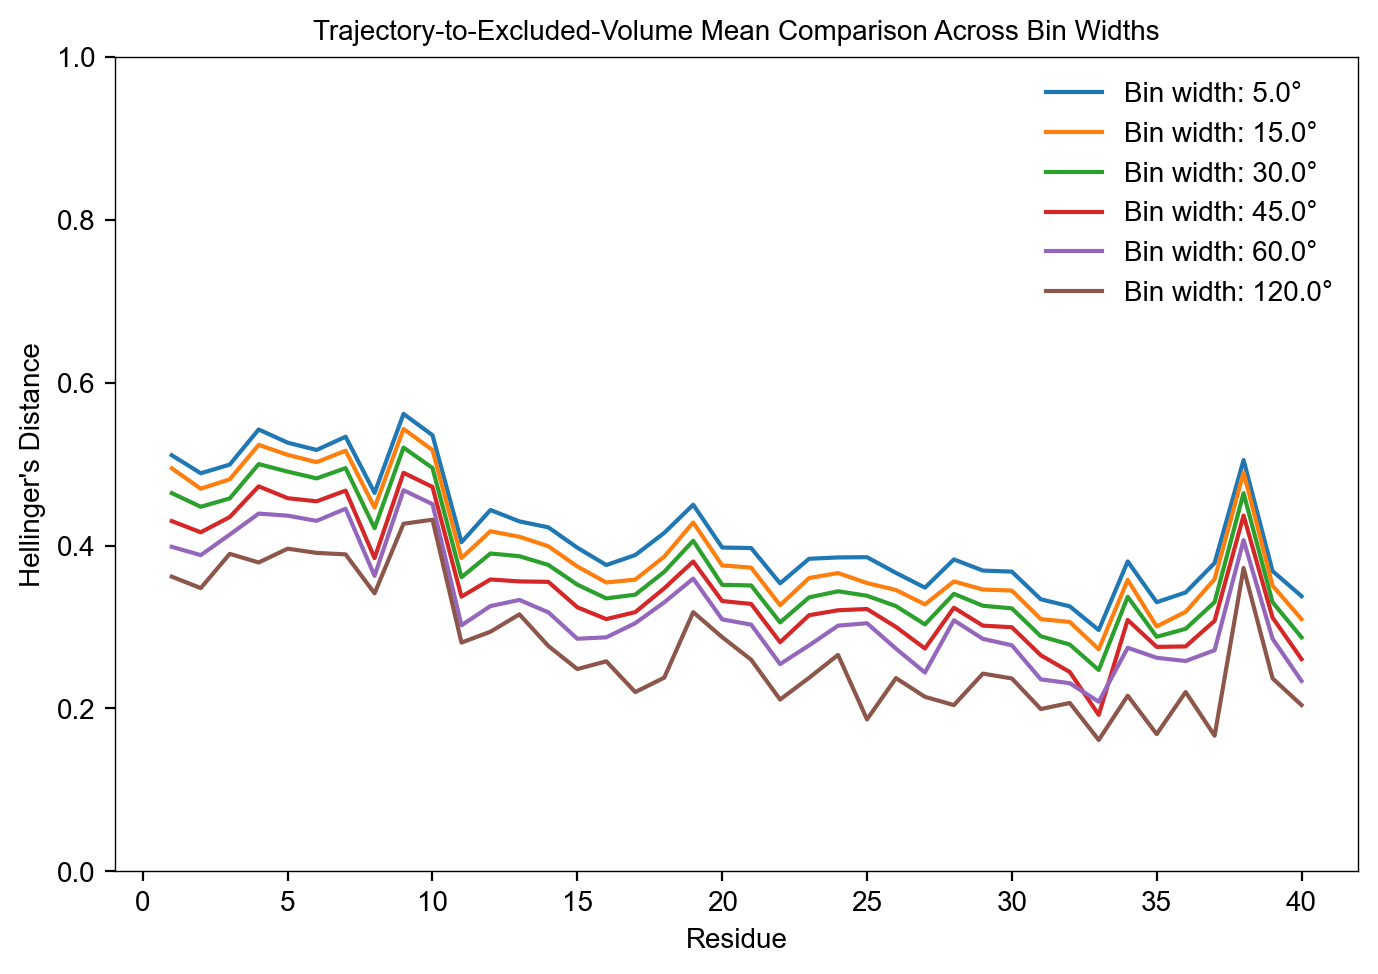

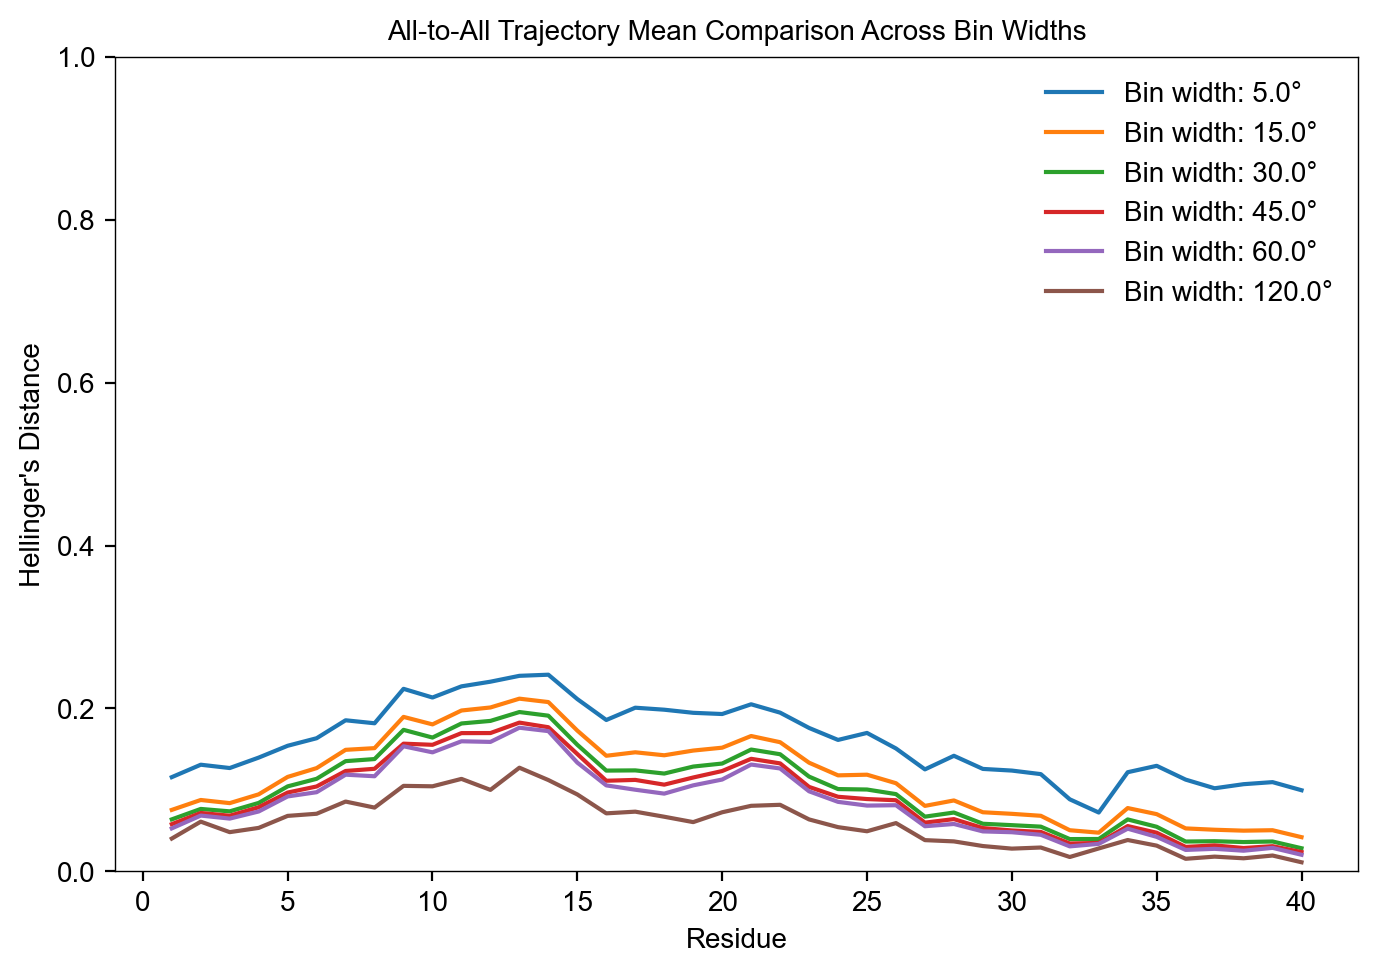

In [4]:
plot_bin_width_comparison(bin_widths, ev_means,
                          "Trajectory-to-Excluded-Volume Mean Comparison Across Bin Widths",
                          save_path=figure_path("si_figures", "synth_traj_to_excluded_volume_mean_bin_width_comparison.pdf"))
plot_bin_width_comparison(bin_widths, ata_means,
                          "All-to-All Trajectory Mean Comparison Across Bin Widths",
                          save_path=figure_path("si_figures", "synth_all_to_all_traj_mean_bin_width_comparison.pdf"))